* ML09 ニューラルネットワーク
  * tensorflow をインストールする
  * Google Colab はインストール済み

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 論理和を学習

Model: "or_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 783ms/step - accuracy: 0.2500 - loss: 1.1137
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.2500 - loss: 1.0664
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2500 - loss: 1.0139
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2500 - loss: 0.9558
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2500 - loss: 0.8926
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2500 - loss: 0.8257
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2500 - loss: 0.7569
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5000 - loss: 0.6882
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5000 - loss: 0.6220
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5000 - loss: 0.5602
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7500 - loss: 0.5044
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7500 - l

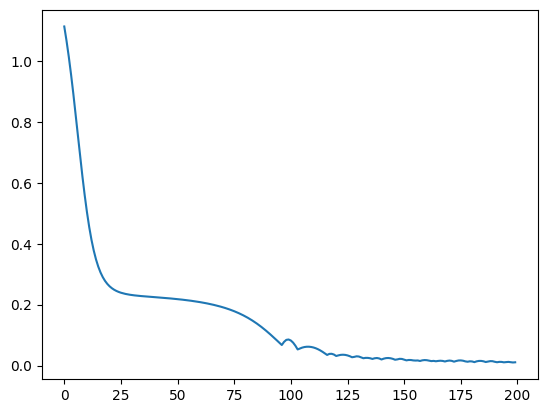

In [ ]:
%%time
# 論理和を学習するためのデータを準備
x = np.array([[0.0, 0.0], [1.0, 0.0], [1.0, 1.0], [0.0, 1.0]])  # x1 と x2 の入力を 4パターン準備
y = np.array([0.0, 1.0, 1.0, 1.0])  # True(1)/False(0) の出力を準備

# ニューラルネットワークのモデルを作成 (サマリを表示)
or_model = tf.keras.models.Sequential(name='or_model') # ニューラルネットワークのモデルの箱を用意
or_model.add(tf.keras.Input(shape=(2,))) # 2入力の入力層 （add でレイヤ(層)等を順に追加していく）
or_model.add(tf.keras.layers.Dense(units=1, activation='tanh')) # セル1個の出力層を用意、活性化関数は tanh
or_model.summary()  # 作成したモデルの中身を表示

# 学習時の設定を行い、学習を実施 (学習中のlossの変化をグラフで表示)
or_model.compile(loss='mean_absolute_error', # 学習時の損失関数
                 optimizer=tf.optimizers.Adam(learning_rate=0.05), # 最適化関数と学習率
                 metrics=['accuracy'])  # 評価関数
history = or_model.fit(x, y, epochs=200, verbose=1) # fit関数で学習を実施 (verboseを設定して学習中のlossを表示)
plt.plot(history.history['loss']) # 学習中のlossの変化をグラフで表示

# 学習で利用したデータと、モデルで推測した結果を表示
print(x)
print(or_model.predict(x, verbose=0))

### iris(アヤメ)の学習

In [ ]:
# sklearnデータセットに収録されたiris(アヤメ)のデータセットをロード
from sklearn.datasets import load_iris
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

# 学習用データを読み込み、特徴量は標準化、ターゲットは one-hot ベクトル化
iris_data = load_iris()
x = preprocessing.scale(iris_data["data"])
print(x[:3])
y = np.identity(3)[iris_data["target"]]
print(y[:3])

# データを学習用とバリデーション用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=1) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]]
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]
x_train:112 x_test:38 y_train:112 y_test:38


Model: "iris_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35 (140.00 B)

 Trainable params: 35 (140.00 B)

 Non-trainable params: 0 (0.00 B)

iris data: accuracy_score: train data : 0.97321  test data : 0.97368


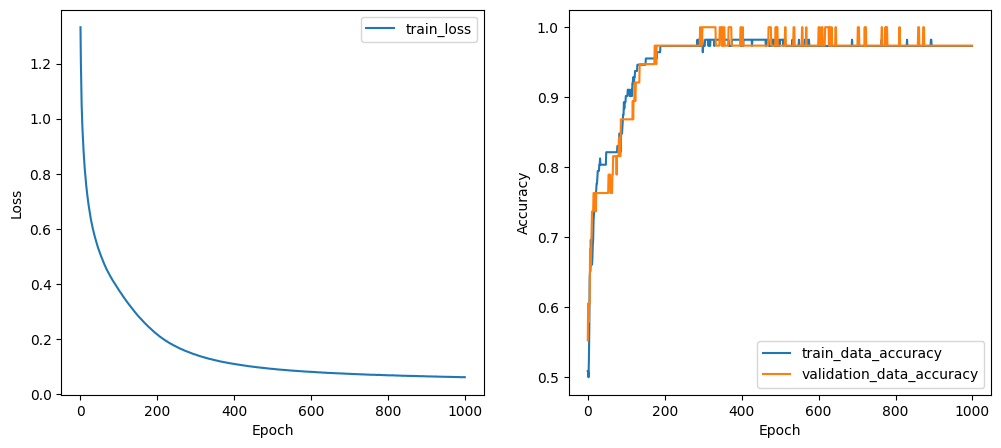

CPU times: user 54.5 s, sys: 26.1 s, total: 1min 20s
Wall time: 1min 8s


In [ ]:
%%time
# ニューラルネットワークのモデルを作成 (サマリを表示) ## 1
iris_model = tf.keras.models.Sequential(name='iris_model') # ニューラルネットワークのモデルの箱を用意
iris_model.add(tf.keras.Input(shape=(4,))) # 4入力の入力層
iris_model.add(tf.keras.layers.Dense(units=4, activation='relu')) # 4入力のセルを1個用意、活性化関数は ReLU
iris_model.add(tf.keras.layers.Dense(units=3, activation='softmax')) # セルを3個からなる出力層を用意、活性化関数はソフトマックス
iris_model.summary()  # 作成したモデルの中身を表示

# 学習時の設定を行い、学習を実施 (学習中のlossの変化をグラフで表示)
iris_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy']) # 学習時の損失関数、最適化関数、評価関数を設定
history = iris_model.fit(x_train, y_train, # 学習用データ
                         epochs=1000, batch_size=10, verbose=0, shuffle=True, # fit関数で学習を実施
                         validation_data=(x_test, y_test))  # validation用のデータを設定

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
train_loss, train_accuracy = iris_model.evaluate(x_train, y_train, verbose=0)
test_loss, test_accuracy = iris_model.evaluate(x_test, y_test, verbose=0)
print(f'iris data: accuracy_score: train data : {train_accuracy:.5f}  test data : {test_accuracy:.5f}')

# 学習中の精度の変化をグラフで表示
fig, ax = plt.subplots(1,2,figsize=(12,5))
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')
ax[0].plot(history.history['loss'], label='train_loss') # 学習中のlossの変化をグラフで表示
ax[0].legend(loc='upper right')
ax[1].plot(history.history['accuracy'], label='train_data_accuracy') # 学習中の学習用データに対する正解率の変化をグラフで表示
ax[1].plot(history.history['val_accuracy'], label='validation_data_accuracy') # 学習中の検証用データに対する正解率の変化をグラフで表示
ax[1].set_ylabel('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend(loc='lower right')
plt.show()

### MNIST の学習

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

# 手書き文字のデータセットを読み込む (訓練用の60000枚のうち6000枚を利用)
(X_train_raw, y_train_raw), (_, _) = tf.keras.datasets.mnist.load_data()
X_train = X_train_raw.reshape(-1, 784).astype("float32")
y_train = y_train_raw.astype("int32")
_, x, _, y = train_test_split(X_train, y_train, test_size=0.1, random_state=1)

# 特徴量は 0-1 の範囲に正規化、ターゲットは one-hot ベクトル化
x = x / 255
print(x[0])
y = np.identity(10)[y]
print(y[:3])

# データを学習用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=1) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.  

Model: "mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

mnist_model, accuracy_score: train data : 1.00000  test data : 0.94267


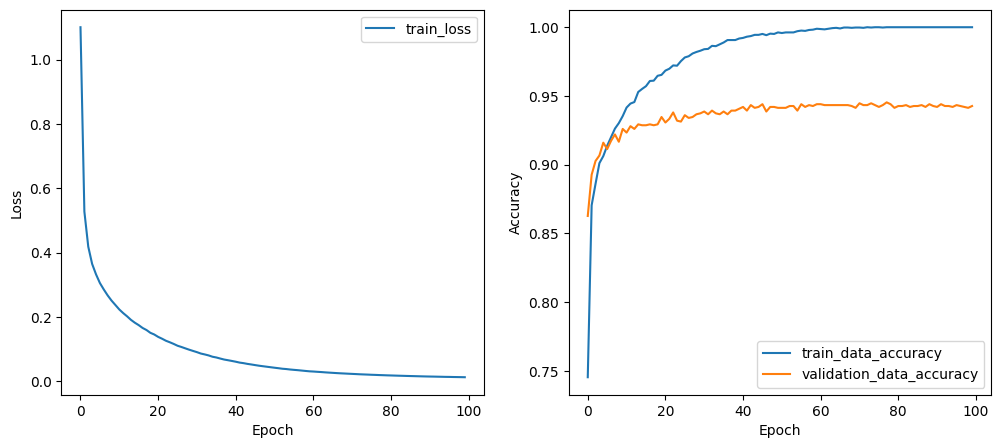

CPU times: user 1min 1s, sys: 6.36 s, total: 1min 8s
Wall time: 38.4 s


In [ ]:
%%time
# ニューラルネットワークのモデルを作成 (サマリを表示)
mnist_model = tf.keras.models.Sequential(name='mnist_model') # ニューラルネットワークのモデルの箱を用意
mnist_model.add(tf.keras.Input(shape=(784,))) # 784入力の入力層
mnist_model.add(tf.keras.layers.Dense(units=784, activation='relu')) # 784入力のセルを784個用意、活性化関数は ReLU
mnist_model.add(tf.keras.layers.Dense(units=10, activation='softmax')) # セルを10個からなる出力層を用意、活性化関数はソフトマックス
mnist_model.summary()  # 作成したモデルの中身を表示

# 学習時の設定を行い、学習を実施 (学習中のlossの変化をグラフで表示)
mnist_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy']) # 学習時の損失関数、最適化関数、評価関数を設定
history = mnist_model.fit(x_train, y_train, epochs=100, batch_size=10, verbose=0, # fit関数で学習を実施
                          validation_data=(x_test, y_test))  # validation用のデータを設定
# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
train_loss, train_accuracy = mnist_model.evaluate(x_train, y_train, verbose=0)
test_loss, test_accuracy = mnist_model.evaluate(x_test, y_test, verbose=0)
print(f'mnist_model, accuracy_score: train data : {train_accuracy:.5f}  test data : {test_accuracy:.5f}')

# 学習中の精度の変化をグラフで表示
fig, ax = plt.subplots(1,2,figsize=(12,5))
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')
ax[0].plot(history.history['loss'], label='train_loss') # 学習中のlossの変化をグラフで表示
ax[0].legend(loc='upper right')
ax[1].plot(history.history['accuracy'], label='train_data_accuracy') # 学習中の学習用データに対する正解率の変化をグラフで表示
ax[1].plot(history.history['val_accuracy'], label='validation_data_accuracy') # 学習中の検証用データに対する正解率の変化をグラフで表示
ax[1].set_ylabel('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend(loc='lower right')
plt.show()

### Fashion MNIST の学習

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

# 手書き文字のデータセットを読み込む (訓練用の60000枚のうち6000枚を利用)
(X_train_raw, y_train_raw), (_, _) = tf.keras.datasets.fashion_mnist.load_data()
X_train = X_train_raw.reshape(-1, 784).astype("float32")
y_train = y_train_raw.astype("int32")
_, x, _, y = train_test_split(X_train, y_train, test_size=0.1, random_state=1)

# 特徴量は 0-1 の範囲に正規化、ターゲットは one-hot ベクトル化
x = x / 255
print(x[0])
y = np.identity(10)[y]
print(y[:3])

# データを学習用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=1) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[0.         0.         0.         0.         0.         0.
 0.         0.00392157 0.00392157 0.         0.         0.
 0.27058825 0.38431373 0.         0.37254903 0.14509805 0.
 0.         0.00392157 0.00392157 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.00392157 0.00392157 0.         0.57254905 0.77254903 0.78039217
 0.77254903 0.827451   0.9254902  0.19607843 0.         0.01176471
 0.00392157 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.01176471 0.
 0.30980393 0.654902   0.8745098  0.89411765 0.92156863 0.9098039
 0.79607844 0.5647059  0.         0.         0.00392157 0.
 0.         0.        

Model: "mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

mnist_model, accuracy_score: train data : 0.99178  test data : 0.84667


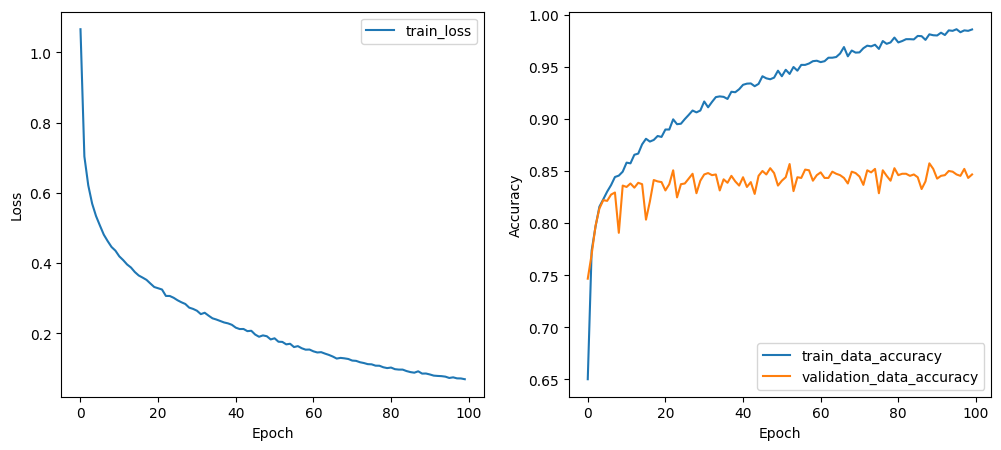

CPU times: user 42.3 s, sys: 5.55 s, total: 47.8 s
Wall time: 36 s


In [ ]:
%%time
# ニューラルネットワークのモデルを作成 (サマリを表示)
mnist_model = tf.keras.models.Sequential(name='mnist_model') # ニューラルネットワークのモデルの箱を用意
mnist_model.add(tf.keras.Input(shape=(784,))) # 784入力の入力層
mnist_model.add(tf.keras.layers.Dense(units=784, activation='relu')) # 784入力のセルを784個用意、活性化関数は ReLU
mnist_model.add(tf.keras.layers.Dense(units=10, activation='softmax')) # セルを10個からなる出力層を用意、活性化関数はソフトマックス
mnist_model.summary()  # 作成したモデルの中身を表示

# 学習時の設定を行い、学習を実施 (学習中のlossの変化をグラフで表示)
mnist_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy']) # 学習時の損失関数、最適化関数、評価関数を設定
history = mnist_model.fit(x_train, y_train, epochs=100, batch_size=10, verbose=0, # fit関数で学習を実施
                          validation_data=(x_test, y_test))  # validation用のデータを設定

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
train_loss, train_accuracy = mnist_model.evaluate(x_train, y_train, verbose=0)
test_loss, test_accuracy = mnist_model.evaluate(x_test, y_test, verbose=0)
print(f'mnist_model, accuracy_score: train data : {train_accuracy:.5f}  test data : {test_accuracy:.5f}')

# 学習中の精度の変化をグラフで表示
fig, ax = plt.subplots(1,2,figsize=(12,5))
ax[0].set_ylabel('Loss')
ax[0].set_xlabel('Epoch')
ax[0].plot(history.history['loss'], label='train_loss') # 学習中のlossの変化をグラフで表示
ax[0].legend(loc='upper right')
ax[1].plot(history.history['accuracy'], label='train_data_accuracy') # 学習中の学習用データに対する正解率の変化をグラフで表示
ax[1].plot(history.history['val_accuracy'], label='validation_data_accuracy') # 学習中の検証用データに対する正解率の変化をグラフで表示
ax[1].set_ylabel('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend(loc='lower right')
plt.show()